# CRISPR-Cas9 guide-RNA efficiency — a DeepHF reproduction and extension

**MLSN F26 Group 2.** One notebook for the whole project: cleaning, Tier 1, Tier 2, Tier 3 and
our extras. It runs on **Google Colab by default** and **locally by uncommenting one block**.

## The paper we are reproducing

Wang et al., *"Optimized CRISPR guide RNA design for two high-fidelity Cas9 variants by deep
learning"*, **Nature Communications 10, 4284 (2019)**. PDF in `docs/paper/`.

The task: given a **21-mer** (the 20-nt spacer plus the first nt of the PAM), predict the **indel
cleavage efficiency** in `[0, 1]` for three Cas9 nucleases — **WT-SpCas9**, **eSpCas9(1.1)** and
**SpCas9-HF1**. The paper's headline metric is the **test Spearman rank correlation ρ**, and its
winning model is a BiLSTM over the sequence with biophysical ("biofeature") inputs concatenated
before the output head.

| Paper model | WT-SpCas9 | eSpCas9(1.1) | SpCas9-HF1 |
|---|---|---|---|
| XGBoost | 0.8454 | 0.8310 | 0.8184 |
| MLP | 0.8416 | 0.8457 | 0.8440 |
| CNN | 0.8455 | 0.8313 | 0.8343 |
| RNN (BiLSTM) | 0.8555 | 0.8491 | 0.8512 |
| RNN + biofeature | **0.8670** | **0.8624** | **0.8603** |

Linear and Ridge appear only as *bars in Fig. 5c–e* (≈0.75–0.79), so we carry them as figure-read
approximations and label them as such — never as exact numbers.

> ### The caveat that is printed under every comparison
> The paper reports the mean ± s.d. of **tenfold shuffled validation** (n = 10). We report a
> **single fixed split** (seed 42) averaged over **3 model-init seeds**. Our numbers are noisier and
> the comparison is **not** a like-for-like significance test. This is a machine-learning course
> reproduction, not biological research: no wet-lab or clinical claims are made anywhere here.

## The three-tier plan

| Tier | Input | Models | Why this tier exists |
|---|---|---|---|
| **Tier 1** | 439 engineered tabular features | Ridge, LightGBM, XGBoost, CatBoost, mean-ensemble | the paper's own tree baseline, and our performance floor |
| **Tier 2** | sequence only | LSTM, BiLSTM, CNN | the paper's RNN and CNN rows: what the sequence alone buys |
| **Tier 3** | sequence + ViennaRNA bio features | BiLSTM+bio, CNN+bio | the paper's winning design, plus the team's multi-kernel GuideCNN |
| **Extras** | beyond the paper | CNN→BiLSTM, Transformer, multi-task (3 enzymes at once), stacking | our extension: can anything beat the paper's design? |

Each tier is an **ablation of the one before it**, which is why **two** things are held constant
across Tier 2 and Tier 3 **by design**: recurrent depth (one layer) and the training schedule
(epochs, batch size and learning rate all come from `MODE`, with no per-model exceptions).
Otherwise "bio features help" would be confounded with "more depth helps" or "more epochs help".

## How to run this

1. **On Colab (the default).** Pick a GPU runtime (A100 or L4 for `MODE = "full"`) and run every
   cell top to bottom. The setup cell clones the repo, installs it, and mounts Drive; every
   artifact is written under the shared Drive project folder.
2. **Locally.** In the setup cell, comment out block **[A] GOOGLE COLAB** and uncomment block
   **[B] LOCAL**. Nothing else in the notebook changes.
3. **First time through, change nothing.** The shipped state — `MODE = "quick"` (3 epochs, 1 seed)
   with `RUN_TIER3` and `RUN_EXTRAS` **off** — proves the whole notebook runs end to end in
   minutes. Tier 3 and the extras are off on purpose: they need section 6's bio features, which
   cost hours of folding *whatever* `MODE` says. For the numbers we report, set `MODE = "full"`
   **and** turn those two switches on.
4. **If the session dies, just re-run the notebook.** Every finished (model, enzyme, seed) is
   already on disk and is skipped; only what is missing is retrained. See section 2 for why that
   is safe even across a `quick` → `full` switch.
5. **Run every cell, every time.** The `RUN_*` switches decide what *trains*; they never decide
   what you execute. Skipping a cell skips a definition the next section needs.

### Section map

| # | Section | # | Section |
|---|---|---|---|
| 1 | Setup (runtime) | 7 | Tier 1 — trees and ensemble |
| 2 | Run settings and project paths | 8 | Tier 2 — LSTM, BiLSTM, CNN |
| 3 | Data acquisition and cleaning | 9 | Tier 3 — BiLSTM+bio, CNN+bio |
| 4 | Exploratory data analysis | 10 | Extras — hybrid, Transformer, multi-task, stacking |
| 5 | Features — 439 tabular + encodings | 11 | Hyper-parameter search (optional, off) |
| 6 | Bio features — computed once, cached | 12 | Results, scoreboard and figures |

---

## 1. Setup — activate exactly one runtime block

**What this does.** Block **[A]** (active) mounts Google Drive, clones the public repo into
`/content`, installs it with `pip install -e .`, and points `PROJECT_ROOT` at the shared Drive
project folder. Code therefore comes from the clone and **all data, caches, model weights and
results live on Drive**, which is what makes a Colab disconnect cheap: everything finished is
still there when you reconnect.

Block **[B]** is the same thing for a laptop and is **commented out**. To go local: comment out
block [A], uncomment block [B].

It also puts `<repo>/src` on `sys.path` and calls `importlib.invalidate_caches()` after the
install. An editable install works by dropping a `.pth` file, and `.pth` files are read only when
the interpreter *starts* — not by a kernel that is already running — so without those two lines the
very first `Run all` can fail with `ModuleNotFoundError` in the next cell.

**What to look at.** The first line of output is the runtime check. If it says `RUNTIME MISMATCH`
in a wall of `!`, you have the wrong block active — it tells you which one to switch to. Then
confirm the two paths it prints (`code` and `project`) are the ones you expect.

In [1]:
# ========================================================================== #
# SECTION 1 - SETUP.  Exactly ONE of the two blocks below may be active.
# Shipped state: the COLAB block [A] is active, the LOCAL block [B] is commented out.
# ========================================================================== #
import importlib.util
import subprocess
import sys
import warnings
from pathlib import Path


def detect_colab() -> bool:
    """True on Google Colab, False anywhere else.

    ``find_spec("google.colab")`` imports the parent ``google`` package before it can
    look inside it, and raises ModuleNotFoundError when no ``google`` package exists at
    all -- which is the normal state of a clean local environment. So the lookup has to
    be guarded: unguarded, the very first cell of the notebook dies locally with
    "No module named 'google'".
    """
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = detect_colab()


def check_runtime(active: str) -> None:
    """Warn loudly when the activated setup block does not match this kernel.

    Called as the FIRST statement of whichever block is active, so the message
    arrives before anything else can fail in a more confusing way.
    """
    detected = "colab" if IN_COLAB else "local"
    if active == detected:
        print(f"runtime check OK: block [{active.upper()}] matches the detected {detected} kernel")
        return
    bar = "!" * 88
    print("\n" + bar)
    print(f"!! RUNTIME MISMATCH: the [{active.upper()}] block is active, but this kernel looks")
    print(f"!! like {detected.upper()}.")
    if detected == "local":
        print("!! FIX: comment out the COLAB block [A] below and uncomment the LOCAL block [B],")
    else:
        print("!! FIX: comment out the LOCAL block [B] below and uncomment the COLAB block [A],")
    print("!!      then re-run this cell.")
    print(bar + "\n")
    warnings.warn(
        f"setup block [{active}] does not match the detected {detected} runtime",
        stacklevel=2,
    )


# -------------------------------------------------------------------------- #
# [A] GOOGLE COLAB   <-- ACTIVE
# -------------------------------------------------------------------------- #
check_runtime("colab")

REPO_URL = "https://github.com/OvaltineSamuel/MLSN_F26_Group2"
# Cloned with an explicit -b: a plain `git clone <url>` takes the repo's DEFAULT branch, so
# a pre-merge click of the README's Colab badge would check out `main`, which does not yet
# contain the crispr_deephf package -- the next cell would then die on ModuleNotFoundError
# with nothing to suggest the branch was the reason.
# ONCE THIS BRANCH IS MERGED: set REPO_BRANCH = "main".
REPO_BRANCH = "refactor/single-colab-notebook"
REPO_DIR = Path("/content/MLSN_F26_Group2")
# The shared Drive project folder. Artifacts written here survive a disconnect.
DRIVE_PROJECT = Path("/content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)")

from google.colab import drive  # Colab-only import, hence not at the top

drive.mount("/content/drive", force_remount=True)

if REPO_DIR.exists():
    # check=False so a diverged or dirty clone cannot abort the session -- but a pull that
    # failed means the code below is STALE, and silently running stale code is how a
    # "fixed" bug reappears in a teammate's run.
    pull = subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull", "--ff-only", "origin", REPO_BRANCH],
        check=False,
    )
    if pull.returncode != 0:
        bar = "!" * 88
        print("\n" + bar)
        print(f"!! git pull --ff-only FAILED (exit {pull.returncode}). The clone at")
        print(f"!! {REPO_DIR} is NOT up to date with origin/{REPO_BRANCH},")
        print("!! so this run uses whatever code that folder already held.")
        print("!! FIX: delete that folder and re-run this cell for a clean clone.")
        print(bar + "\n")
        warnings.warn(
            f"stale clone: git pull --ff-only exited {pull.returncode}", stacklevel=2
        )
else:
    subprocess.run(
        ["git", "clone", "-b", REPO_BRANCH, REPO_URL, str(REPO_DIR)], check=True
    )
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-e", f"{REPO_DIR}[deep,boosters]"],
    check=True,
)
# An editable install drops a .pth file, and .pth files are read only at interpreter
# START -- never by an already-running kernel. Without these two lines the very first
# "Run all" can fail with ModuleNotFoundError in the next cell.
sys.path.insert(0, str(REPO_DIR / "src"))
importlib.invalidate_caches()

PROJECT_ROOT = DRIVE_PROJECT  # code from the clone, data/results on Drive
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
print(f"code   : {REPO_DIR}")
print(f"project: {PROJECT_ROOT}")

# -------------------------------------------------------------------------- #
# [B] LOCAL
# ...to go local: comment out the COLAB block above, then uncomment every line
# ...below the sentinel (in Jupyter/Colab: select them and press Ctrl-/).
# -------------------------------------------------------------------------- #
# --- uncomment from here ---
# check_runtime("local")
#
# REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# subprocess.run(
#     [sys.executable, "-m", "pip", "install", "-q", "-e", f"{REPO_DIR}[deep,boosters]"],
#     check=True,
# )
# # .pth files are read only at interpreter start, not by a running kernel:
# sys.path.insert(0, str(REPO_DIR / "src"))
# importlib.invalidate_caches()
# PROJECT_ROOT = REPO_DIR  # the repo working tree is the project root
# print(f"code   : {REPO_DIR}")
# print(f"project: {PROJECT_ROOT}")

Mounted at /content/drive
code   : /content/MLSN_F26_Group2
project: /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)


## 2. Run settings and project paths

**What this does.** Imports the `crispr_deephf` package — the tested library that holds *all* of
this project's logic — and resolves the project directories under `PROJECT_ROOT`.

**Why the logic is not in this notebook.** Three older notebooks (`01_data_cleaning`,
`02_tier1_baselines`, `CNN_Train`) each carried their own copy of the cleaning and feature code and
had already drifted apart. Everything now lives in `src/crispr_deephf/`, under a pytest suite that
runs on CPU against a synthetic dataset, and this notebook holds only the narrative, the calls and
the results. The teammate files in
`models/` are untouched; `models/README.md` explains that the notebook uses the package copy.

**What to look at.** The six directories it prints (they are created if missing), and the
availability line: `cuda available: True` on a GPU runtime, and `ViennaRNA`/`Biopython` `True`
(Tier 3 and the bio extras need both).

In [2]:
import joblib
import numpy as np
import pandas as pd
import torch

from crispr_deephf import (
    architectures,
    benchmark,
    bio_features,
    config,
    data,
    features,
    plots,
    runner,
    tuning,
)

plots.set_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

paths = config.get_paths(PROJECT_ROOT)
print(f"project root      : {paths.root}")
print(f"raw data          : {paths.data_raw}")
print(f"processed data    : {paths.data_processed}")
print(f"bio-feature cache : {paths.cache}")
print(f"model weights     : {paths.models}")
print(f"results (json)    : {paths.results}")
print(f"figures           : {paths.figures}")
print()
print(f"torch {torch.__version__} | cuda available: {torch.cuda.is_available()}")
print(f"ViennaRNA: {bio_features.VIENNA_AVAILABLE} | Biopython: {bio_features.BIOPYTHON_AVAILABLE}")
print(f"Optuna: {tuning.OPTUNA_AVAILABLE}")
print(f"registered architectures ({len(architectures.MODEL_REGISTRY)}): "
      f"{sorted(architectures.MODEL_REGISTRY)}")

project root      : /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)
raw data          : /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)/data/raw
processed data    : /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)/data/processed
bio-feature cache : /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)/data/cache
model weights     : /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)/models
results (json)    : /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)/results
figures           : /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)/results/figures

torch 2.14.1+cu130 | cuda available: True
ViennaRNA: True | Biopython: True
Optuna: True
registered architectures (8): ['BiLSTM', 'BiLSTM+bio', 'CNN', 'CNN+bio', 'CNN-BiLSTM', 'LSTM', 'MultiTask-BiLSTM+bio', 'Transformer']


### 2b. The switches

**What this does.** Everything you are likely to change lives in the next cell.

- **`MODE`** — **ships as `"quick"`**: 3 epochs, patience 2, **1 seed**. That is a smoke
  test, never a reported result, and it is the shipped default on purpose — a notebook six people
  share should not start hours of GPU training the first time somebody presses *Run all*.
  **For the run we report, change that one line to `MODE = "full"`**: 60 epochs, patience 10,
  **3 model-init seeds** per deep model (the paper's own models were trained to convergence, and a
  mean ± s.d. over seeds is the honest way to present a single-split result). Within a mode
  **every deep model trains on the same schedule** — same epochs, same batch size, same learning
  rate, no per-model exceptions — because that is what makes the tier deltas in sections 8 and 9
  mean what those sections say they mean. The teammate's grid-searched `BiLSTM` schedule survives
  as `runner.TUNED_OVERRIDES`, which **no run mode applies**; see section 8.
- **`RUN_TIER3` and `RUN_EXTRAS` ship as `False`, and the reported run needs both `True`.** They
  are the only tiers that touch section 6's bio features, and `MODE` does not make those cheap: a
  quick Tier-3 + extras run still folds the enzyme's **full** row set inside `run_deep_model` —
  **230,961 sequences, about 2.5 h** — before the first reported epoch. Off, as shipped, quick mode
  really is the minutes-long end-to-end check section 1 promises. See section 6 for the measured
  cost before you turn them on.
- **`RUN_TIER1/2/3/EXTRAS`** — turn *training* on and off. Results already on disk are still picked
  up by section 12 regardless, so switching a tier off does not blank the scoreboard.
- **`RUN_TUNING = False`** — the Optuna search in section 11 is hours of GPU time and is **off**.
- **`FORCE_RERUN = False`** — leave it `False`. `True` discards every saved result and retrains
  from scratch.
- **`SEEDS`** — derived from `MODE`, never set by hand, so the seed count and the recorded mode
  settings can never disagree.

**Why re-running is safe (this is the part worth understanding).** Each finished
(model, enzyme, seed) is written to its own JSON file in `results/` *atomically*. On a re-run,
a seed is skipped only if its saved file is readable **and** its recorded mode settings (name,
epochs, patience, batch size, lr), its data hash and its target list all match the current run.
So a `quick` result can never be mistaken for a `full` one, and a changed dataset invalidates
everything automatically. That is what makes a Colab disconnect cost one model instead of a day.

**What to look at.** The summary this cell prints: mode, seeds, device, and the number of deep
training runs the settings imply. In `quick` mode it reminds you that the numbers are not results.
In `full` mode, if `DEVICE` says `cpu`, stop and switch to a GPU runtime.

In [3]:
# Ships as "quick" (3 epochs, 1 seed) = end-to-end smoke test, never a reported result.
# CHANGE THIS ONE LINE to "full" (60 epochs, 3 seeds) for the run we report.
MODE = "quick"
RUN_TIER1 = True       # Ridge / LightGBM / XGBoost / CatBoost / mean-ensemble on 439 features
RUN_TIER2 = True       # LSTM, BiLSTM, CNN                       (sequence only)
# Tier 3 and the extras ship OFF: both need section 6's bio features, and a quick run folds
# the enzyme's FULL row set anyway (~231k sequences, ~2.5 h). TURN BOTH ON for the real run.
RUN_TIER3 = True      # BiLSTM+bio, CNN+bio                     (sequence + bio features)
RUN_EXTRAS = True     # CNN-BiLSTM, Transformer, multi-task, stacking
RUN_TUNING = False     # Optuna search (section 11) - hours of GPU time, deliberately off
FORCE_RERUN = False    # True = ignore every saved result and retrain from scratch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODE_SETTINGS = config.get_mode(MODE)          # KeyError on a typo, rather than a silent default
SEEDS = list(range(MODE_SETTINGS["n_seeds"]))  # derived, so seeds and recorded settings agree

#: The one multi-output architecture. Safe ONLY on `shared_split` (see section 10).
MULTITASK_MODEL = "MultiTask-BiLSTM+bio"
assert MULTITASK_MODEL in architectures.EXTRA_MODELS
SINGLE_TARGET_EXTRAS = [m for m in architectures.EXTRA_MODELS if m != MULTITASK_MODEL]

_n_single = len(architectures.TIER2_MODELS) * RUN_TIER2 \
    + len(architectures.TIER3_MODELS) * RUN_TIER3 \
    + len(SINGLE_TARGET_EXTRAS) * RUN_EXTRAS
print(f"MODE        : {MODE} -> {MODE_SETTINGS}")
print(f"SEEDS       : {SEEDS}")
print(f"DEVICE      : {DEVICE}")
print(f"FORCE_RERUN : {FORCE_RERUN}")
print(f"switches    : tier1={RUN_TIER1} tier2={RUN_TIER2} tier3={RUN_TIER3} "
      f"extras={RUN_EXTRAS} tuning={RUN_TUNING}")
print(f"deep training runs implied: {_n_single} models x 3 enzymes x {len(SEEDS)} seeds "
      f"+ {int(RUN_EXTRAS)} multi-task x {len(SEEDS)} seeds "
      f"= {_n_single * 3 * len(SEEDS) + int(RUN_EXTRAS) * len(SEEDS)} "
      "(already-finished runs are skipped)")
if MODE == "quick":
    print("\nMODE = 'quick': 3 epochs, 1 seed - an end-to-end smoke test, NOT a result.")
    print("Set MODE = 'full' at the top of this cell for the run we report.")
elif DEVICE == "cpu":
    print("\n*** MODE is 'full' but no GPU was found. Switch to a GPU runtime, or use "
          "MODE = 'quick'. ***")
if not (RUN_TIER3 or RUN_EXTRAS):
    print("\nRUN_TIER3 and RUN_EXTRAS are OFF (the shipped state): nothing below folds a single")
    print("bio feature, which is what keeps this pass to minutes. Turn BOTH on for the reported")
    print("run - section 6 says what that costs.")

MODE        : quick -> {'epochs': 3, 'n_seeds': 1, 'patience': 2, 'batch_size': 256}
SEEDS       : [0]
DEVICE      : cuda
FORCE_RERUN : False
switches    : tier1=True tier2=True tier3=True extras=True tuning=False
deep training runs implied: 7 models x 3 enzymes x 1 seeds + 1 multi-task x 1 seeds = 22 (already-finished runs are skipped)

MODE = 'quick': 3 epochs, 1 seed - an end-to-end smoke test, NOT a result.
Set MODE = 'full' at the top of this cell for the run we report.


### 2c. The one helper every deep tier uses

**What this does.** Defines `run_single_target(model_name)`, used by Tier 2, Tier 3 and the
single-target extras, so each of those sections is three lines.

**Why it is written this way — the data-leak rule.** The train/val/test splits are drawn **per
enzyme** (`WT_split`, `eSp_split`, `HF1_split`), independently, because the three enzymes were
measured on overlapping but different guide sets and the paper's 76.5/8.5/15 ratios are applied
per enzyme. A consequence: *one guide can be WT-**train** and HF1-**test***. So a single-target
run must read **that enzyme's own split column**, and `runner.run_deep_model` additionally calls
`data.filter_for_target` internally to drop rows with no measurement for that enzyme — a missing
value can never reach a model as if it were real. A model with a 3-output head trained this way
would be scored on guides it was trained on, which is exactly the warning the team left in
`models/CNN.py:16`; section 10 handles that case with `shared_split` instead.

**What to look at.** For each run the package prints an `integrity ok: <n> rows, data hash <h>`
line (sequences are `[ACGT]{21}`, targets are finite and in `[0, 1]`, and no sequence appears in
two splits), then the per-split row counts, then per-epoch training output. A line with no epochs
under it means that seed was **resumed from disk**, not retrained.

In [4]:
def split_col_for(target_col: str) -> str:
    """The frozen per-enzyme split column for one target, e.g. 'WT_Efficiency' -> 'WT_split'."""
    return f"{config.TARGET_KEYS[target_col]}_split"


def run_single_target(model_name: str) -> list[dict]:
    """Train `model_name` on each enzyme separately, on that enzyme's own frozen split.

    One output head, one enzyme, per-enzyme split column: the only safe combination for the
    independently drawn per-enzyme splits (see the note above).
    """
    out: list[dict] = []
    for target_col in config.TARGET_COLS:
        split_col = split_col_for(target_col)
        print(f"\n=== {model_name} | {config.TARGET_LABELS[target_col]} | split '{split_col}' ===")
        out += runner.run_deep_model(
            df,
            model_name=model_name,
            target_cols=[target_col],
            split_col=split_col,
            paths=paths,
            mode=MODE,
            seeds=SEEDS,
            device=DEVICE,
            force=FORCE_RERUN,
        )
    return out


print("helper ready: run_single_target(model_name)")

helper ready: run_single_target(model_name)


## 3. Data acquisition and cleaning

**What this does.** Produces (or loads) `data/processed/deephf_clean_all.csv`: the paper's
supplementary table, cleaned, with the train/val/test splits **frozen into the file itself**.

**Where the raw file comes from**, in order: (1) the Drive project folder's `data/raw/`,
(2) an automatic download of the Nature supplementary data, (3) failing both, an error message
telling you where to upload it by hand. The download goes to a `.part` file and is renamed only
after a zip-magic check passes, so an interrupted transfer or an HTML error page served with
HTTP 200 (think Colab behind a captive portal) can never be installed as "the dataset".

**What cleaning means here.** Column names standardised, PAM typos repaired, then *assertions*:
every efficiency is in `[0, 1]`, every guide is `N20` + `NGG`. These are assertions and not
filters on purpose — if the raw file ever changes shape we want a crash, not a quietly different
dataset.

**Why the splits are frozen into the CSV.** The paper holds out 15% for test and takes 10% of the
remainder for validation (76.5 / 8.5 / 15), per enzyme, and we use seed 42. Writing the labels
into the file means the modelling sections *read* the partition instead of re-deriving it, so no
two sections can ever disagree about which guide is in which split — a bug the three old notebooks
were wide open to. `shared_split` is an extra, single partition over **all** rows, used only by
the multi-task model in section 10.

**What to look at.** The row count (59,852 in the paper's table) and the first few rows: the
`21mer`, the three efficiency columns, and the four split columns.

In [5]:
clean_csv = paths.data_processed / config.CLEAN_ALL_CSV

if clean_csv.exists() and not FORCE_RERUN:
    df = data.load_clean(clean_csv)
    print(f"loaded cleaned dataset from {clean_csv}")
else:
    raw_path = data.ensure_raw_excel(paths, allow_download=True)
    print(f"raw file: {raw_path}")
    raw = data.load_raw(raw_path)
    print(f"raw shape: {raw.shape}")

    clean = data.clean_and_validate(raw)
    data.assert_unique_sequences(clean)   # the splits are index-based: a duplicate would leak
    clean = data.add_split_labels(clean)  # WT_split / eSp_split / HF1_split, seed 42
    clean = data.add_shared_split(clean)  # one split per guide, for the multi-task model only
    clean.to_csv(clean_csv, index=False)
    print(f"wrote {clean_csv}")
    df = data.load_clean(clean_csv)       # re-read, so both branches give identical dtypes

print(f"\ncleaned shape: {df.shape}")
print(f"columns: {list(df.columns)}")
df.head()

raw file: /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)/data/raw/41467_2019_12281_MOESM3_ESM.xlsx
raw shape: (59852, 7)
wrote /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)/data/processed/deephf_clean_all.csv

cleaned shape: (59852, 11)
columns: ['gRNA_ID', 'gRNA_Seq', 'PAM', '21mer', 'WT_Efficiency', 'eSpCas9_Efficiency', 'SpCas9_HF1_Efficiency', 'WT_split', 'eSp_split', 'HF1_split', 'shared_split']


,gRNA_ID,gRNA_Seq,PAM,21mer,WT_Efficiency,eSpCas9_Efficiency,SpCas9_HF1_Efficiency,WT_split,eSp_split,HF1_split,shared_split
0,GRNA-1,AAAAAAAAACTCCAAAACCC,TGG,AAAAAAAAACTCCAAAACCCT,0.168570,0.142063,0.093147,train,train,train,train
1,GRNA-2,AAAAAACAACAAGAAGCACA,AGG,AAAAAACAACAAGAAGCACAA,0.099624,0.051901,0.064951,train,train,val,train
2,GRNA-3,AAAAAACACAAGCAAGACCG,TGG,AAAAAACACAAGCAAGACCGT,0.247750,0.043573,0.061797,train,train,train,train
3,GRNA-4,AAAAAACAGATGCCACCTGT,GGG,AAAAAACAGATGCCACCTGTG,0.141232,0.052343,0.057246,train,train,train,train
4,GRNA-5,AAAAAACCCGTAGATAGCCT,CGG,AAAAAACCCGTAGATAGCCTC,0.045803,0.046234,0.067596,test,test,test,test


### 3b. The frozen splits

**What this does.** Counts rows per split label for all four split columns.

**What to look at.** The three per-enzyme columns should each sit near **76.5 / 8.5 / 15 %** of
*their own* valid rows — and their totals differ from each other, because each enzyme was measured
on a different number of guides. `shared_split` covers **all** rows and is the only column where
a guide has the same split for every enzyme. If any `test_%` is far from 15, the split did not
come from this pipeline and nothing downstream should be trusted.

In [6]:
rows = []
for col in [split_col_for(t) for t in config.TARGET_COLS] + [config.SHARED_SPLIT_COL]:
    counts = data.split_counts(df, col)
    total = sum(counts.values())
    rows.append({
        "split_col": col,
        "train": counts.get("train", 0),
        "val": counts.get("val", 0),
        "test": counts.get("test", 0),
        "labelled rows": total,
        "train_%": round(100 * counts.get("train", 0) / total, 2),
        "val_%": round(100 * counts.get("val", 0) / total, 2),
        "test_%": round(100 * counts.get("test", 0) / total, 2),
    })
print(f"paper ratios: train 76.5 / val 8.5 / test 15.0, seed {config.RANDOM_SEED}\n")
pd.DataFrame(rows)

paper ratios: train 76.5 / val 8.5 / test 15.0, seed 42



,split_col,train,val,test,labelled rows,train_%,val_%,test_%
0,WT_split,42536,4727,8341,55604,76.5,8.5,15.0
1,eSp_split,44841,4983,8793,58617,76.5,8.5,15.0
2,HF1_split,43518,4836,8534,56888,76.5,8.5,15.0
3,shared_split,45786,5088,8978,59852,76.5,8.5,15.0


## 4. Exploratory data analysis

**What this does.** Per-enzyme summary statistics of the three efficiency targets, including how
many measurements are missing.

**Why it matters for the modelling.** The missing counts are not noise to be filled in: a guide
with no eSpCas9 measurement is simply absent from the eSpCas9 task, which is why the splits are
per enzyme and why `data.filter_for_target` drops those rows rather than imputing them.

**What to look at.** `count` vs `missing_NaN` per enzyme, and whether the three means and
quartiles are comparable (they are not identical — the high-fidelity variants cut less
efficiently on average, which the paper also reports).

In [7]:
data.summary_table(df)

,count,missing_NaN,mean,median,std,min,25%,75%,max
WT_Efficiency,55604.0,4248,0.726451,0.801859,0.217595,0.018182,0.608765,0.896144,1.0
eSpCas9_Efficiency,58617.0,1235,0.358294,0.341355,0.187470,0.007143,0.205487,0.496129,1.0
SpCas9_HF1_Efficiency,56888.0,2964,0.478405,0.500584,0.206519,0.008547,0.335453,0.635574,1.0


### 4b. Our guide counts beside the paper's — and a discrepancy worth a slide

**What this does.** Counts the valid measurements per enzyme in the supplementary table and puts
them next to the counts stated in the paper's own text (`config.PAPER_N_GUIDES`).

**The finding.** WT-SpCas9 (55,604) and SpCas9-HF1 (56,888) match the article **exactly**. For
eSpCas9(1.1) the article's text says **58,167** while its own Supplementary Data contains
**58,617** — 450 more. Two exact matches either side rule out a cleaning bug on our end, and
58,167 vs 58,617 *looks like* a digit transposition — a typo in the published text is our
inference from two exact matches and one transposed pair, not an established fact. We keep the paper's
published number in `config.PAPER_N_GUIDES` because that constant is explicitly *the paper's
number*, and report the difference instead of quietly papering over it.

**Why it changes nothing about our results.** No model uses this count; it is a reporting detail.
It is here because "our number disagrees with the paper" is exactly the kind of thing that must be
*shown*, not discovered by a grader.

**What to look at.** The `Difference` column: two zeros and one `+450`.

In [8]:
rows = []
for target_col, key in config.TARGET_KEYS.items():
    ours = int(df[target_col].notna().sum())
    paper = config.PAPER_N_GUIDES[key]
    rows.append({
        "Enzyme": config.TARGET_LABELS[target_col],
        "Ours (supplementary data)": ours,
        "Paper (article text)": paper,
        "Difference": ours - paper,
    })
counts_vs_paper = pd.DataFrame(rows)
print(counts_vs_paper.to_string(index=False))

print(f"\nrows in the supplementary table: {len(df)}  (paper: 59,852)")
print(
    "\nFINDING - the paper's text disagrees with its own Supplementary Data for eSpCas9(1.1):\n"
    "  article text   : 58,167 valid eSpCas9(1.1) guides\n"
    "  supplementary  : 58,617 (counted above) - 450 more\n"
    "  WT (55,604) and HF1 (56,888) match the article exactly, which rules out a cleaning bug\n"
    "  on our side; 58,167 vs 58,617 looks like a digit transposition in the published text\n"
    "  (our inference from two exact matches and one transposed pair, not established fact).\n"
    "  config.PAPER_N_GUIDES deliberately keeps the PAPER's value: it is the paper's number.\n"
    "  Nothing in the pipeline uses this count, so no result is affected."
)

      Enzyme  Ours (supplementary data)  Paper (article text)  Difference
   WT-SpCas9                      55604                 55604           0
eSpCas9(1.1)                      58617                 58167         450
  SpCas9-HF1                      56888                 56888           0

rows in the supplementary table: 59852  (paper: 59,852)

FINDING - the paper's text disagrees with its own Supplementary Data for eSpCas9(1.1):
  article text   : 58,167 valid eSpCas9(1.1) guides
  supplementary  : 58,617 (counted above) - 450 more
  WT (55,604) and HF1 (56,888) match the article exactly, which rules out a cleaning bug
  on our side; 58,167 vs 58,617 looks like a digit transposition in the published text
  (our inference from two exact matches and one transposed pair, not established fact).
  config.PAPER_N_GUIDES deliberately keeps the PAPER's value: it is the paper's number.
  Nothing in the pipeline uses this count, so no result is affected.


### 4c. Efficiency distributions (paper Fig. 2d)

**What this does.** Overlays the three enzymes' efficiency distributions, the same view as the
paper's Fig. 2d, and saves it to `results/figures/`.

**Why the paper shows this.** It is the justification for the whole modelling setup: efficiency is
continuous and spread across `[0, 1]` rather than clustered at the ends, so this is a **regression**
problem scored by rank correlation, not a "good guide / bad guide" classification.

**What to look at.** Three broad, unimodal, overlapping distributions. WT-SpCas9 should sit
furthest right (it cuts most efficiently); the two high-fidelity variants shift left. Any spike at
exactly 0 or 1 would mean clipping somewhere upstream.

saved /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)/results/figures/fig02d_efficiency_distributions.png


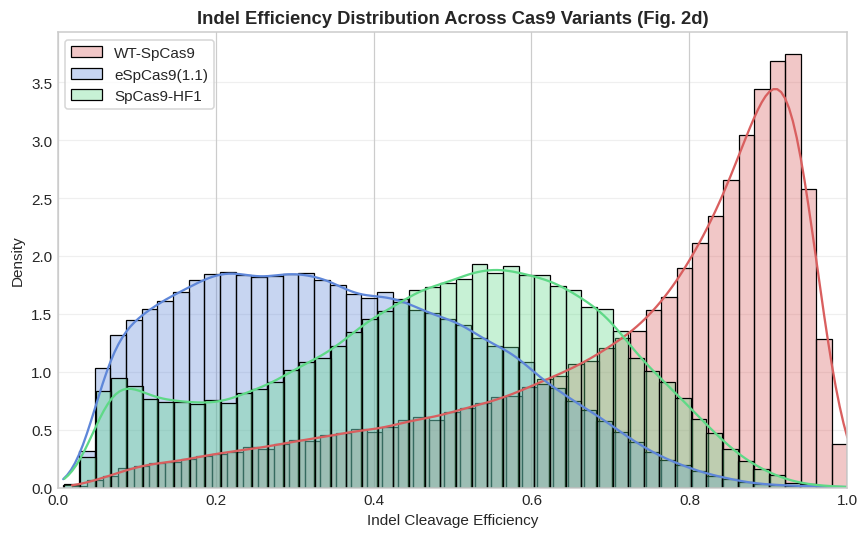

In [9]:
fig = plots.plot_efficiency_distributions(df)
out = paths.figures / "fig02d_efficiency_distributions.png"
fig.savefig(out, dpi=200, bbox_inches="tight")
print(f"saved {out}")

## 5. Features — 439 tabular features and the sequence encodings

**What this does.** Builds the two input representations the whole project uses, both from the
21-mer only (no bio features yet — those are section 6).

**The 439 engineered features** (Tier 1's input), vectorised over the whole table:

| Group | Count | What it captures |
|---|---|---|
| positional single-nucleotide one-hot | 21 × 4 = 84 | "an A at position 17" |
| positional adjacent dinucleotides | 20 × 16 = 320 | local stacking / sequence context |
| global single-nt counts and frequencies | 8 | overall composition |
| global dinucleotide counts (20-mer) | 16 | composition at the pair level |
| total and regional GC content | 7 | GC drives binding strength |
| biological motifs (poly-T, poly-G, purine runs) | 4 | known efficiency killers (poly-T ends transcription) |

**Why the paper does it this way.** Trees cannot read a sequence, so position and context have to
be spelled out as columns. The paper's own XGBoost row is built on exactly this kind of positional
one-hot plus composition set, which is what makes our Tier 1 comparable to it.

**The sequence encodings** (Tier 2/3's input): integer tokens `(N, 21)` for embedding layers, and a
one-hot tensor `(N, 21, 4)` — the paper's `x ∈ R^(21×4)`. The deep models take the one-hot
transposed to `(N, 4, 21)`, which `torch_data.build_splits` does for us.

**What to look at.** `X.shape == (n_rows, 439)` and the assertion passing. The timing line tells
you roughly how long this takes (seconds, not minutes — it is all numpy).

In [10]:
X, feature_names = features.extract_crispr_features(df["21mer"].astype(str).tolist())
int_tokens, one_hot = features.encode_sequences(df["21mer"].astype(str).tolist())

print(f"\ntabular X        : {X.shape}  ({len(feature_names)} names)")
print(f"integer tokens   : {int_tokens.shape}  dtype {int_tokens.dtype}")
print(f"one-hot tensor   : {one_hot.shape}  dtype {one_hot.dtype}")
assert X.shape == (len(df), features.N_FEATURES) == (len(df), 439)
print(f"\nfirst 6 feature names : {feature_names[:6]}")
print(f"last 6 feature names  : {feature_names[-6:]}")

Extracted 439 features for 59,852 sequences in 0.88s (100.2 MB).

tabular X        : (59852, 439)  (439 names)
integer tokens   : (59852, 21)  dtype int64
one-hot tensor   : (59852, 21, 4)  dtype float32

first 6 feature names : ['pos_1_A', 'pos_1_C', 'pos_1_G', 'pos_1_T', 'pos_2_A', 'pos_2_C']
last 6 feature names  : ['gc_content_nonseed', 'gc_diff_seed_nonseed', 'poly_T_ge4', 'poly_T_ge3', 'poly_G_ge4', 'purine_ratio']


## 6. Bio features — the expensive step, cached and gated

**What this does.** Pre-computes the team's ViennaRNA/Biopython biophysical feature set and writes
it to the cache in `data/cache/`, so the Tier-3 and extras runs read it instead of recomputing it.
It is **skipped** unless a tier that needs it is switched on *and* `MODE` is `"full"` — see the
gate note below.

**What the features are.** Per guide: GC content and counts, mono- and dinucleotide counts,
regional melting temperatures (`tm_1_4`, `tm_5_13`, `tm_16_20`), folding energies of the spacer
alone and of the spacer joined to the 81-nt sgRNA scaffold (`mfe_spacer`, `mfe_full`,
`mfe_difference`), ensemble energy and diversity, **scaffold integrity** (how much of the
scaffold's own fold the spacer disrupts), and mean accessibility — plus three per-position
channels over the 21 positions (`p_unpaired`, `p_intra`, `p_scaffold`). Flattened that is
`bio_features.N_BIO_FEATURES == 100` numbers per guide.

**Why the paper uses them.** Its best model is "RNN + biofeature": the sequence alone does not say
whether the guide will fold back on itself or fight the scaffold, and a guide that is sequestered
in secondary structure cannot load into Cas9. Adding these features is the single biggest jump in
the paper's table (RNN 0.8555 → RNN+bio 0.8670 on WT).

**What it really costs — read this before you start a full run.** ViennaRNA folds a 21-nt
spacer *and* a 102-nt spacer+scaffold construct, and computes a base-pair probability matrix,
**per guide**. The cache is keyed by a **sha256 of the whole row set it was asked for**, not by
individual sequence, so each of the four row sets below is folded independently even though they
overlap almost completely:

| cache file | rows folded |
|---|---|
| `bio_WT` | 55,604 |
| `bio_eSp` | 58,617 |
| `bio_HF1` | 56,888 |
| `bio_MULTI` | 59,852 |
| **total** | **230,961 folds for 59,852 distinct guides — about 3.9x the minimum** |

**Measured cost, not a guess.** Timed on this project's own cleaned guides,
single-threaded, on **one core of the machine this was developed on** (x86-64 Intel, CPU
family 6 model 167 — 11th-generation "Rocket Lake" class, 12 logical cores; Windows,
Python 3.12, ViennaRNA 2.8.0): 1,000 sequential `compute_bio_features` calls took 38.7 s,
i.e. **38.7 ms per guide** (a 200-guide sample gave 39.4 ms, so the figure is stable, and
two separate runs of the pipeline itself came out at 38.5 ms/guide). The arithmetic:

```
  38.7 ms x  55,604 (bio_WT)    =  36 min
  38.7 ms x  58,617 (bio_eSp)   =  38 min
  38.7 ms x  56,888 (bio_HF1)   =  37 min
  38.7 ms x  59,852 (bio_MULTI) =  39 min
  -------------------------------------------
  38.7 ms x 230,961 total       = 149 min  ~= 2.5 hours
```

So: **about 2.5 hours of pure folding** on that core, roughly 37 minutes per cache file.
**A Colab vCPU may differ in either direction — we have not measured one**, so read 2.5 h as
the order of magnitude rather than a promise; what the measurement settles is that this step
costs hours, not tens of minutes. Keying the cache per *sequence* so the subsets
could reuse each other's work would cut it to the `bio_MULTI` figure alone (~39 min, a 3.9x
saving); that is a change inside `bio_features`/`runner`, recorded as a follow-up and
deliberately not attempted from the notebook. This note exists so the bill is not a surprise.
What the content key *does* buy is safety: a cache file built from a different dataset is
recomputed rather than silently reused — the one defect fixed relative to the original
`models/Bio_Features.py`.

**So this cell is gated three ways.** It pre-warms nothing unless `RUN_TIER3` or `RUN_EXTRAS` is on
(Tier 1 and Tier 2 are sequence-only and never touch bio features); it is skipped when ViennaRNA or
Biopython is missing; and in `MODE = "quick"` it skips the pre-warm and says so, because the whole
point of quick mode is a *fast* end-to-end check. **So `MODE = "quick"` with `RUN_TIER3` and
`RUN_EXTRAS` off — which is exactly how the notebook ships — folds nothing at all.**

**The converse, so nobody is misled:** quick mode does not make bio features cheap. A quick Tier-3
run still folds that enzyme's full row set once, inside `run_deep_model`, because the model needs
the features no matter how few epochs it trains for. Skipping the pre-warm only avoids folding row
sets that nothing is about to train on.

**What to look at.** On a full run: one `saved bio features to ...` line per cache file the first
time, and one `loaded cached bio features from ...` line per file on every later run, for four
files — one per enzyme (the exact filtered row sets Tier 3 trains on) plus `bio_MULTI` for the
multi-task model. Otherwise, the one line naming the gate that skipped it.

In [11]:
if not (RUN_TIER3 or RUN_EXTRAS):
    print("RUN_TIER3 and RUN_EXTRAS are both off -> nothing below needs bio features.")
    print("Skipping the pre-warm entirely (Tier 1 and Tier 2 are sequence-only).")
elif not (bio_features.VIENNA_AVAILABLE and bio_features.BIOPYTHON_AVAILABLE):
    print("*** ViennaRNA / Biopython missing: Tier 3 and the bio extras cannot run. ***")
    print("    pip install ViennaRNA biopython   (or re-run the setup cell)")
elif MODE == "quick":
    print("MODE = 'quick' -> skipping the pre-warm, which would fold ~231k sequences.")
    print("The Tier-3 / extras runs below compute and cache bio features themselves, for only")
    print("the row sets they actually train on. For a run that folds NOTHING, also switch")
    print("RUN_TIER3 and RUN_EXTRAS off.")
else:
    # The cache key is the whole row set, so pre-warm exactly the row sets the runs will use:
    # one per enzyme (after filter_for_target) plus the multi-task frame (shared_split).
    bio_frames = {
        config.TARGET_KEYS[t]: data.filter_for_target(df, t) for t in config.TARGET_COLS
    }
    keep = df[config.SHARED_SPLIT_COL].notna() & df[config.TARGET_COLS].notna().any(axis=1)
    bio_frames[runner.MULTI_KEY] = df.loc[keep].reset_index(drop=True)

    for key, bio_frame in bio_frames.items():
        glob, chans = bio_features.bio_matrix(
            bio_frame["21mer"].astype(str).tolist(),
            cache_path=paths.cache / f"bio_{key}",
        )
        flat = bio_features.flatten_bio(glob, chans)
        print(f"{key:>5}: globals {glob.shape} + channels {chans.shape} -> flat {flat.shape}")
        assert flat.shape[1] == bio_features.N_BIO_FEATURES == 100
    print(f"\n{len(bio_features.GLOBAL_FEATURE_NAMES)} global features + "
          f"{len(bio_features.POSITIONAL_CHANNEL_NAMES)} channels x {bio_features.SEQ_LEN} "
          f"positions = {bio_features.N_BIO_FEATURES}")
    print(f"folded {sum(len(f) for f in bio_frames.values())} rows for "
          f"{len(df)} distinct guides (the row sets overlap; see the note above)")

MODE = 'quick' -> skipping the pre-warm, which would fold ~231k sequences.
The Tier-3 / extras runs below compute and cache bio features themselves, for only
the row sets they actually train on. For a run that folds NOTHING, also switch
RUN_TIER3 and RUN_EXTRAS off.


## 7. Tier 1 — trees and the ensemble (439 tabular features)

**What this does.** Trains Ridge, LightGBM, XGBoost and CatBoost on the 439 features, per enzyme,
reading the frozen per-enzyme split, then builds a **mean-ensemble** of whichever gradient boosters
are installed. Every fitted model is dumped to `models/` and every result to `results/`.

**Why these models.** Ridge is the linear floor the paper also shows (as a bar in Fig. 5c–e);
XGBoost is a row in the paper's table, so this is a direct reproduction. The paper's point is that
trees on engineered features already reach ρ ≈ 0.82–0.85, and that the deep models' gain over that
is real but modest — which is the argument our three tiers are built to test.

**Honest detail.** Only the boosters that imported successfully are trained (section 2 printed
which). The ensemble needs at least two and is rebuilt from the boosters' *saved predictions*, so
it also works in a resumed session.

**One warning you will see, and should not fix.** scikit-learn prints
`LinAlgWarning: An ill-conditioned matrix detected` once per enzyme while Ridge fits. That is
correct and expected: the 439 features are deliberately collinear (the four one-hot columns at
each position sum to 1, and the global counts are linear combinations of the positional ones).
Ridge's L2 penalty is exactly the tool for a collinear design, and its result lands on the
paper's own Ridge bar (≈0.78 on WT), so nothing is wrong. Dropping features to silence the
warning would change the feature set the rest of the project is defined against.

**What to look at.** `integrity ok` per enzyme, then the count of results. The numbers themselves
come out in section 12 — resist reading individual lines here.

In [12]:
tier1_results = []
if RUN_TIER1:
    tier1_results = runner.run_tier1(df, X, feature_names, paths=paths, force=FORCE_RERUN)
    print(f"\nTier 1: {len(tier1_results)} (model, enzyme) results")
    print(sorted({r["model_name"] for r in tier1_results}))
else:
    print("RUN_TIER1 = False -> skipped. Results already on disk are still used in section 12.")

integrity ok: 55604 rows, data hash d50af8cbdfd3


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


integrity ok: 58617 rows, data hash 4b6537f22ab6


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


integrity ok: 56888 rows, data hash 42f4aa833fbc


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



Tier 1: 15 (model, enzyme) results
['CatBoost', 'Ensemble', 'LightGBM', 'Ridge', 'XGBoost']


### 7b. What the trees actually learned

**What this does.** Loads the saved XGBoost model for WT-SpCas9 and plots its 25 most important
features.

**Why look.** It is the cheapest sanity check in the notebook. The paper reports that positions
near the PAM dominate, with GC content and poly-T motifs close behind. If the top features were
instead scattered uniformly across positions 1–20, our feature matrix would be misaligned with the
sequence and every Tier-1 number would be meaningless.

**What to look at.** `pos_17..pos_21` style features and `gc_*` near the top, and the overall
shape — one or two dominant features with a long tail.

saved /content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)/results/figures/fig_feature_importance_xgboost_WT.png


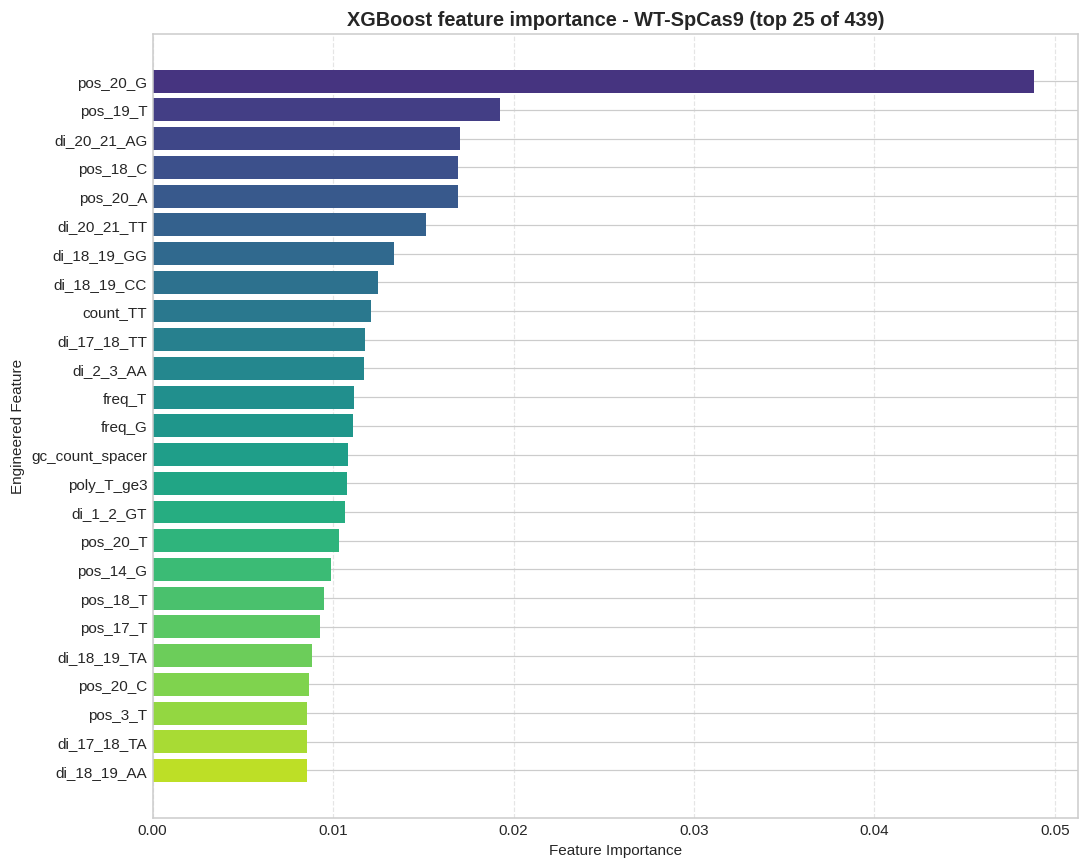

In [13]:
imp_path = paths.models / f"xgboost_{config.TARGET_KEYS[config.TARGET_COLS[0]]}.joblib"
if imp_path.exists():
    fitted = joblib.load(imp_path)
    fig = plots.plot_feature_importance(
        list(feature_names),
        np.asarray(fitted.feature_importances_),
        "XGBoost feature importance - WT-SpCas9 (top 25 of 439)",
        top_n=25,
    )
    out = paths.figures / "fig_feature_importance_xgboost_WT.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    print(f"saved {out}")
else:
    print(f"{imp_path.name} not found - run section 7 with RUN_TIER1 = True first.")

## 8. Tier 2 — LSTM, BiLSTM, CNN (sequence only)

**What this does.** Trains the three sequence-only architectures, each on each enzyme separately,
`len(SEEDS)` seeds apiece.

**Why these three.** They are the paper's own deep rows. Its `RNN` is a **single BiLSTM layer**
over the 21 positions, and its `CNN` a 1-D convolutional stack; the plain `LSTM` is ours, added so
the `LSTM` → `BiLSTM` gap shows what *bidirectionality* alone buys.

**That claim holds only because two axes are pinned, by design.** Every recurrent model in the
registry pins `rnn_layers = 1` (the teammate's grid-searched architecture, and what the paper
used), **and** every deep model in every tier trains on its mode's own schedule — the same epochs,
batch size and learning rate. Depth *and* schedule held constant is what leaves exactly one
difference between `LSTM` and `BiLSTM`: the backward pass. A per-model schedule would confound that
delta as surely as extra depth would, and earlier on this branch it did — the Tier-2 `BiLSTM` ran
20 epochs at lr 0.0005 / batch 128 while `LSTM` ran 60 at lr 0.001 / batch 256, which made this
sentence false. Those grid-searched values still exist, as `runner.TUNED_OVERRIDES`: no run mode
applies them, and a result produced with them must be reported separately and labelled as tuned,
because it is no longer schedule-matched against `LSTM` or against Tier 3.

**Why no bio features here.** That is the whole point of the tier split. Tier 2 is the
sequence-only ceiling; Tier 3 adds exactly one thing on top of it.

**What to look at.** Per-epoch `train_loss / val_loss / val_rho` lines, and whether `val_rho`
plateaus before the epoch budget runs out (early stopping with the mode's patience handles it if
not). Seeds that print no epochs were resumed from disk.

In [14]:
tier2_results = []
if RUN_TIER2:
    for model_name in architectures.TIER2_MODELS:
        tier2_results += run_single_target(model_name)
    print(f"\nTier 2: {len(tier2_results)} (model, enzyme, seed) results")
else:
    print("RUN_TIER2 = False -> skipped. Results already on disk are still used in section 12.")


=== LSTM | WT-SpCas9 | split 'WT_split' ===
integrity ok: 55604 rows, data hash d50af8cbdfd3
integrity ok: 55604 rows, data hash d50af8cbdfd3
train: 42536, val: 4727, test: 8341

=== LSTM | eSpCas9(1.1) | split 'eSp_split' ===
integrity ok: 58617 rows, data hash 4b6537f22ab6
integrity ok: 58617 rows, data hash 4b6537f22ab6
train: 44841, val: 4983, test: 8793

=== LSTM | SpCas9-HF1 | split 'HF1_split' ===
integrity ok: 56888 rows, data hash 42f4aa833fbc
integrity ok: 56888 rows, data hash 42f4aa833fbc
train: 43518, val: 4836, test: 8534

=== BiLSTM | WT-SpCas9 | split 'WT_split' ===
integrity ok: 55604 rows, data hash d50af8cbdfd3
integrity ok: 55604 rows, data hash d50af8cbdfd3
train: 42536, val: 4727, test: 8341

=== BiLSTM | eSpCas9(1.1) | split 'eSp_split' ===
integrity ok: 58617 rows, data hash 4b6537f22ab6
integrity ok: 58617 rows, data hash 4b6537f22ab6
train: 44841, val: 4983, test: 8793

=== BiLSTM | SpCas9-HF1 | split 'HF1_split' ===
integrity ok: 56888 rows, data hash 42f4aa

## 9. Tier 3 — BiLSTM+bio and CNN+bio (sequence + bio features)

**What this does.** The same per-enzyme, multi-seed training as Tier 2, with the 100 cached bio
features fed through a small MLP branch and concatenated with the sequence representation before
the output head.

**Why this is the headline tier.** `BiLSTM+bio` *is* the paper's winning "RNN + biofeature" design
— reproducing it is the core of this project. `CNN+bio` is the team's own multi-kernel GuideCNN
with the same bio branch, so we can see whether the paper's choice of recurrent over convolutional
was the right one on this data.

**The detail that makes these numbers trustworthy.** The bio features are standardised with a
scaler **fit on the training rows only** and then applied to validation and test. Fitting it on all
rows would leak test-set distribution information into training and inflate every number here.

**Why that gap is a measurement and not a coincidence.** `BiLSTM+bio` and Tier 2's `BiLSTM`
differ in **one** thing: the bio branch. Same architecture otherwise, same recurrent depth
(`rnn_layers = 1`), and the same training schedule — epochs, batch size and learning rate all come
from `MODE`, and nothing is overridden per model (see section 8). So the difference between the two
rows is attributable to the features, which is the entire reason the tiers are split here.

**What to look at.** `BiLSTM+bio` should be our best single-target model, and the gap over Tier 2's
`BiLSTM` is the direct measure of what bio features buy. The paper's gap is about **+0.012** ρ.

In [15]:
tier3_results = []
if RUN_TIER3 and bio_features.VIENNA_AVAILABLE:
    for model_name in architectures.TIER3_MODELS:
        tier3_results += run_single_target(model_name)
    print(f"\nTier 3: {len(tier3_results)} (model, enzyme, seed) results")
elif RUN_TIER3:
    print("*** RUN_TIER3 = True, but ViennaRNA is NOT importable, and every Tier-3 model needs")
    print("    the bio features -> nothing trained. The setup cell's [deep] extra installs it:")
    print("    re-run section 1, then section 6, then this cell. ***")
else:
    print("RUN_TIER3 = False -> skipped. Results already on disk are still used in section 12.")


=== BiLSTM+bio | WT-SpCas9 | split 'WT_split' ===
integrity ok: 55604 rows, data hash d50af8cbdfd3
integrity ok: 55604 rows, data hash d50af8cbdfd3
bio features: 2000/55604
bio features: 4000/55604
bio features: 6000/55604


KeyboardInterrupt: 

## 10. Extras — beyond the paper

**What this does.** Trains the two single-target extensions: a **CNN→BiLSTM hybrid** (convolutions
extract local motifs, the BiLSTM reads them in order) and a **Transformer encoder** with learned
positional embeddings (self-attention over the 21 positions, so position 3 can attend to position
19 directly). Both take the bio branch.

**Why try them.** The paper's model is from 2019 and the obvious 2026 questions are "does attention
beat recurrence on a 21-token sequence?" and "does a convolutional front-end help the BiLSTM?".
A 21-token sequence is short, so neither is guaranteed to help — a negative result here is a
finding, not a failure, and we report it either way.

**What to look at.** Whether either exceeds `BiLSTM+bio` from Tier 3. Watch the Transformer for
overfitting: 21 tokens and ~50k rows is not much data for self-attention.

In [ ]:
extra_results = []
if RUN_EXTRAS and bio_features.VIENNA_AVAILABLE:
    for model_name in SINGLE_TARGET_EXTRAS:
        extra_results += run_single_target(model_name)
    print(f"\nSingle-target extras: {len(extra_results)} (model, enzyme, seed) results")
elif RUN_EXTRAS:
    print("*** RUN_EXTRAS = True, but ViennaRNA is NOT importable, and both single-target extras")
    print("    take the bio branch -> nothing trained. See the Tier-3 cell above for the fix. ***")
else:
    print("RUN_EXTRAS = False -> skipped. Results already on disk are still used in section 12.")

### 10b. The multi-task model — and the one place `shared_split` is mandatory

**What this does.** Trains one BiLSTM+bio with a **3-output head** that predicts all three enzymes
at once, on the `shared_split` column.

**Why it might win.** The three enzymes are the same protein with different fidelity mutations;
whatever makes a guide good is largely shared. One model learning all three gets three times the
supervision per shared parameter, and a guide measured for only one enzyme still contributes
(unmeasured entries are masked out of the loss rather than treated as zero).

**Why it is dangerous, and what stops it.** The per-enzyme split columns are drawn
**independently**, so one guide can be WT-**train** and HF1-**test**. A 3-output head trained on
that guide's WT row has already seen it when it is scored on the HF1 test set — a data leak that
would silently inflate the result. This is the team's own warning from `models/CNN.py:16`.
`shared_split` is a single partition over all rows: a guide has the **same** split for every
enzyme, so the leak is impossible. `runner.run_deep_model` **refuses** with a `ValueError` if a
multi-target run is given anything else — the guard runs before any data is touched, so you cannot
get a wrong number out of it by accident.

**What to look at.** The split column in the header line must be `shared_split`. Validation ρ is
reported per enzyme as well as averaged, so you can see whether one enzyme is dragging the shared
representation around.

In [ ]:
multitask_results = []
if RUN_EXTRAS and bio_features.VIENNA_AVAILABLE:
    print(f"=== {MULTITASK_MODEL} | all 3 enzymes | split '{config.SHARED_SPLIT_COL}' ===")
    multitask_results = runner.run_deep_model(
        df,
        model_name=MULTITASK_MODEL,
        target_cols=list(config.TARGET_COLS),   # 3 outputs ...
        split_col=config.SHARED_SPLIT_COL,      # ... so this MUST be the shared split
        paths=paths,
        mode=MODE,
        seeds=SEEDS,
        device=DEVICE,
        force=FORCE_RERUN,
    )
    print(f"\nMulti-task: {len(multitask_results)} seed results")
elif RUN_EXTRAS:
    print("*** RUN_EXTRAS = True, but ViennaRNA is NOT importable, and the multi-task model takes")
    print("    the bio branch -> nothing trained. See the Tier-3 cell above for the fix. ***")
else:
    print("RUN_EXTRAS = False -> skipped. Results already on disk are still used in section 12.")

### 10c. Stacking the best tree with the best deep model

**What this does.** For each enzyme, picks the best tree model and the best deep model **by mean
validation ρ**, averages the deep model's seeds into one prediction vector, and fits a Ridge
meta-learner on top of the two.

**Why stack at all.** Trees on engineered features and a BiLSTM on the raw sequence make different
mistakes; a linear combination of two decorrelated predictors usually beats both. This is the one
model in the notebook with no counterpart in the paper.

**The rule that keeps it honest.** The meta-learner is fitted on the **validation**-split
predictions and only then scored on test. Fitting it on test predictions is textbook test-set
leakage; the package never does it. Because of that, the stack's *validation* metrics are in-sample
and optimistic — **report its test row only**. Model selection also uses validation ρ, never test.

**What to look at.** The two component names chosen per enzyme, and whether the stack's test ρ
exceeds both of them. A `skipping stack` line means one of the two families has no saved
predictions yet for that enzyme (run sections 7–9 first).

In [ ]:
stack_results = []
if RUN_EXTRAS:
    saved_so_far = runner.load_results(paths.results)
    for target_col in config.TARGET_COLS:
        try:
            payload = runner.run_stack(
                saved_so_far, df, target_col=target_col, paths=paths, mode_name=MODE
            )
        except ValueError as exc:
            print(f"skipping stack for {config.TARGET_LABELS[target_col]}: {exc}")
            continue
        stack_results.append(payload)
        print(f"{config.TARGET_LABELS[target_col]:>14}: {payload['model_name']} "
              f"(meta fitted on '{payload['meta_fit_split']}', coefficients "
              f"{[round(c, 4) for c in payload['meta_coef']]})")
    print(f"\nStacks built: {len(stack_results)}")
else:
    print("RUN_EXTRAS = False -> skipped. Results already on disk are still used in section 12.")

## 11. Hyper-parameter search (optional — **off by default**)

**What this does.** Nothing, unless you set `RUN_TUNING = True`. Then it runs an Optuna TPE search
over one model's architecture and optimisation hyper-parameters, maximising **validation** ρ, and
saves the winner to `results/best_params.json`.

**Why it is off.** The registry's *architecture* defaults already come from a teammate's
completed grid search (`notebooks/BiLSTM.ipynb`) and from the paper. A 40-trial search is hours of GPU time for a gain we
have not shown we need, and leaving it on by default would quietly turn a 2-hour notebook into an
overnight one.

**Why the search only ever sees validation data.** Tuning against the test split would make every
comparison in section 12 optimistic — we would be choosing the model that happens to fit our test
set. `search_deep` never trains or scores on test.

**Resumability.** Passing a `storage=` SQLite URL persists finished trials, so a disconnected
session loses at most one trial. Two caveats: the TPE sampler is re-created with `seed=0`, so a
resumed run can re-propose configurations from its random start-up phase; and resuming with a
different `epochs` or `device` mixes incomparable trial values under one study name — keep both
fixed.

**If you do run it:** the printed params are **not** applied automatically. `apply_best_params`
splits them into `build_model(...)` overrides and training kwargs; wiring them into section 8/9 is
a deliberate, separate edit. Two things to say out loud if you do it: tuned params that change
`rnn_layers` away from 1 leave the Tier-2 vs Tier-3 ablation no longer **depth**-matched, and tuned
`lr` / `batch_size` / `epochs` applied to one model leave it no longer **schedule**-matched (the
same reason `runner.TUNED_OVERRIDES` is opt-in — see section 8). Either way the result has to be
reported separately and labelled as tuned, not dropped into the tier tables.

In [ ]:
TUNE_MODELS = ["BiLSTM+bio"]              # single-output models only
TUNE_TARGET = "WT_Efficiency"
TUNE_TRIALS = 40
TUNE_EPOCHS = 20

if not RUN_TUNING:
    print("RUN_TUNING = False -> no search. Set it to True in section 2 to enable.")
elif not tuning.OPTUNA_AVAILABLE:
    print("optuna is not installed: pip install optuna")
else:
    best_params_path = paths.results / "best_params.json"
    study_db = f"sqlite:///{(paths.results / 'optuna_study.db').as_posix()}"
    for model_name in TUNE_MODELS:
        found = tuning.search_deep(
            df,
            model_name=model_name,
            target_col=TUNE_TARGET,
            split_col=split_col_for(TUNE_TARGET),
            paths=paths,
            n_trials=TUNE_TRIALS,
            epochs=TUNE_EPOCHS,
            device=DEVICE,
            storage=study_db,
        )
        tuning.save_best_params(best_params_path, model_name, found["best_params"])
        overrides, train_kwargs = tuning.apply_best_params(
            tuning.load_best_params(best_params_path, model_name)
        )
        print(f"\n{model_name}: best validation rho {found['best_value']:.4f}")
        print(f"  build_model overrides : {overrides}")
        print(f"  training kwargs       : {train_kwargs}")
    print(f"\nsaved to {best_params_path}. NOT applied automatically - see the note above.")

## 12. Results

**What this does.** Reads **every** result JSON on disk — not just what this session trained — and
aggregates it: one row per `(model, enzyme, split)` with the mean and s.d. of each metric over
seeds.

**Why read from disk rather than from the variables above.** It makes the section independent of
which switches were on, and it means a resumed session reports the full picture. It is also the
reason turning a tier off does not blank the scoreboard.

**How to read `n_seeds` and the s.d.** The s.d. is the sample s.d. (ddof = 1), so it is **NaN** for
anything run with one seed — the deterministic trees, the stack, and everything in `quick` mode.
NaN there is correct and is shown as `n/a`; a `0.0` would be a lie about certainty we do not have.

**Metrics.** Spearman ρ is the headline (it is the paper's); Pearson *r*, RMSE, MAE and R² sit
alongside it to describe calibration and explained variance.

**What to look at.** The `Test` rows, sorted by ρ. Check `n_seeds` is 3 for the deep models in a
full run, and check the mode in the file names if a number looks surprising — a stray `quick`
result cannot be mistaken for a `full` one by the resume logic, but it will still appear in this
table if it is on disk.

**One row is not comparable to the others.** `MultiTask-BiLSTM+bio` is scored on the
`shared_split` test set; every other row is scored on that enzyme's own per-enzyme test split.
Those are different sets of guides, so its ρ is not a row-to-row comparison. The next three cells
print that warning under each table and figure.

**If `results/` is empty** (every `RUN_*` switch off and nothing trained yet) this cell says so and
sections 12b–12e report that there is nothing to compare, instead of raising — so the notebook
still runs top to bottom with everything turned off.

In [ ]:
#: The multi-task model is the only one on `shared_split`, so its test set is a different
#: set of guides from every per-enzyme row. Printed under each table below.
MULTITASK_NOTE = (
    f"NOT ROW-COMPARABLE: {MULTITASK_MODEL} is scored on the '{config.SHARED_SPLIT_COL}' test "
    "set, while every other row uses that enzyme's own per-enzyme test split - different guides, "
    "so its rho is not a like-for-like comparison with the rows beside it."
)

saved = runner.load_results(paths.results)
results_long = runner.results_frame(saved)
HAVE_RESULTS = not results_long.empty

if not HAVE_RESULTS:
    agg = results_long
    n_candidates = 0
    table = results_long
    print(f"no results found in {paths.results}.")
    print("Sections 12b-12e have nothing to report and will say so. Turn a RUN_* switch on "
          "and re-run sections 7-10.")
else:
    agg = runner.aggregate(results_long)
    print(f"{len(saved)} saved result files -> {len(results_long)} rows -> "
          f"{len(agg)} (model, enzyme, split) groups")

    test_agg = agg[agg["Split"] == "Test"].copy()
    n_candidates = int(test_agg["Model"].nunique())
    print(f"{n_candidates} distinct models have test results\n")

    # Which run mode each (model, enzyme) actually came from. `results/` is a SHARED Drive
    # folder, so one teammate smoke-testing in quick mode while another runs full is the
    # normal way a row ends up pooling both - and pooling them makes the mean and s.d.
    # meaningless (one quick seed at 0.40 beside two full seeds at 0.86/0.87 reads as
    # 0.71 +/- 0.27). `runner.aggregate` warns above; this column is how you see which row.
    modes = (
        results_long[results_long["Split"] == "Test"]
        .groupby(["Model", "Target"])["Mode"]
        .agg(lambda s: "+".join(sorted({str(m) for m in s.dropna()})) or "unknown")
        .rename("Mode")
    )
    test_agg = test_agg.merge(modes, on=["Model", "Target"], how="left")
    mixed = sorted(test_agg.loc[test_agg["Mode"].str.contains(r"\+"), "Model"].unique())
    if mixed:
        print(f"*** {len(mixed)} model(s) pool seeds from more than one run mode: "
              f"{', '.join(mixed)}.")
        print("    Their mean and s.d. mix training budgets and are NOT reportable. Move or "
              "delete\n    the results of the mode you are not reporting, then re-run this "
              "cell. ***\n")

    show = ["Model", "Target", "Mode", "n_seeds", "Spearman_rho_mean", "Spearman_rho_std",
            "Pearson_r_mean", "RMSE_mean", "R2_mean"]
    table = test_agg.sort_values(["Target", "Spearman_rho_mean"], ascending=[True, False])[show]

#: Model-init seeds this run actually has, passed to every printed caveat below.
#: `config.PAPER_CAVEAT` used to claim "averaged over 3 model-init seeds" unconditionally,
#: which described a method quick mode never used - printed beside a table reading "n/a".
N_SEEDS_THIS_RUN = int(results_long["Seed"].nunique()) if HAVE_RESULTS else None

table

### 12b. Scoreboard — ours vs the paper, per enzyme

**What this does.** Puts our test ρ next to the paper's number for every model that *has* a paper
counterpart, and prints the comparability caveat underneath.

**The honesty rules this table enforces** (they are in the package, not in this notebook, so they
cannot be forgotten):

- only `Split == "Test"` rows are ever scored — a validation number is never a headline;
- a model with no counterpart in the paper gets a **blank** paper column and can never "beat" it,
  so our Transformer is not quietly credited with beating a model the paper never built;
- Ridge and Linear were read off Fig. 5c–e, so they are labelled `figure (approx)` and a win over
  them must exceed the ~0.01 reading tolerance before it is claimed;
- a missing s.d. stays `n/a`, never `0`.

**What to look at.** The `Beats paper` column, and the `Delta` next to it. `within reading error`
means the comparison is to a figure-read number and the difference is inside the tolerance — i.e.
no claim either way.

In [ ]:
sb = None
if not HAVE_RESULTS:
    print("no results on disk -> no scoreboard. See the message in section 12.")
else:
    sb = benchmark.scoreboard(agg)
    print(benchmark.format_scoreboard(sb).to_string(index=False))
    print("\nCAVEAT: " + benchmark.format_caveat(N_SEEDS_THIS_RUN))
    print(f"\n({int(sb['Paper_source'].eq('').sum())} of {len(sb)} rows have no paper "
          "counterpart and are shown blank rather than as a win.)")
    print("\n" + MULTITASK_NOTE)

### 12c. Our best model per enzyme vs the paper's best

**What this does.** Takes our single best test model per enzyme and sets it against the paper's
best (`RNN + biofeature`), then prints **two** notes: the comparability caveat and the
**selection-bias** note.

**Why the selection-bias note is not optional.** Our "best" is chosen *post hoc from every model we
trained, scored on the test set*; the paper's number is its one reported model. That is a
best-of-N vs single-number comparison and it is biased in our favour. The note says so in words,
beside the table, every time. It is printed explicitly here — the package also attaches it to
`result.attrs["selection_note"]`, but pandas `attrs` do not survive every operation, so relying on
them would mean the note silently disappearing one day.

**What to look at.** `Best_has_paper_counterpart`: if it is `False`, our winner is a model the
paper never built, which weakens the comparison further. And `tier_best` below it — the real
question of this project is whether each tier bought anything over the one before.

In [ ]:
if not HAVE_RESULTS:
    print("no results on disk -> no best-per-enzyme comparison. See section 12.")
else:
    best = benchmark.best_per_target(agg)
    print(best.to_string(index=False))
    # Printed explicitly, NOT read out of the frame's pandas metadata dict: that
    # metadata does not survive every operation, and a caveat that can vanish is
    # not a caveat.
    print("\nSELECTION BIAS: " + benchmark.format_selection_note(n_candidates))
    print("\nCAVEAT: " + benchmark.format_caveat(N_SEEDS_THIS_RUN))

    print("\n" + MULTITASK_NOTE)

    print("\n\nBest model per tier and enzyme:")
    print(benchmark.tier_best(agg).to_string(index=False))
    print("\n" + MULTITASK_NOTE)

### 12d. Slide-ready figures

**What this does.** Saves the presentation figures to `results/figures/`:

- `fig_ours_vs_paper.png` — grouped bars, ours vs paper, one panel per enzyme. Our bars carry a
  ± s.d. error bar **only** where a s.d. exists; paper bars from the article text are solid grey
  and figure-read approximations are hatched, so the two kinds of paper number are never confused.
  The comparability caveat is the figure caption.
- `fig_tier_progression.png` — best ρ per tier, one line per enzyme, each point labelled with the
  winning model. This is the figure that answers "did Tier 3 earn its complexity?", so it carries
  two captions: the comparability caveat, and a note that each point is a per-tier **maximum** over
  **unequal** candidate pools (Tier 1 up to 6 models, Tier 2 three, Tier 3 two). The bigger pool is
  favoured, so part of any step between tiers is best-of-N selection rather than architecture —
  read a *small* rise as "no clear gain", not as a win.
- `fig_model_comparison.png` — Pearson *r* and Spearman ρ for the top five models.

**What to look at.** In the tier-progression figure, a flat line between Tier 2 and Tier 3 would
mean bio features bought nothing on our split — a legitimate result that contradicts the paper and
would need explaining, not hiding.

In [ ]:
if not HAVE_RESULTS:
    print("no results on disk -> no comparison figures. See section 12.")
else:
    figures = {
        "fig_ours_vs_paper": plots.plot_vs_paper(sb),
        "fig_tier_progression": plots.plot_tier_progression(agg),
    }

    test_long = results_long[results_long["Split"] == "Test"]
    top5 = test_long.groupby("Model")["Spearman_rho"].mean().nlargest(5).index
    figures["fig_model_comparison"] = plots.plot_model_comparison(
        test_long[test_long["Model"].isin(top5)]
    )

    for name, figure in figures.items():
        out = paths.figures / f"{name}.png"
        figure.savefig(out, dpi=200, bbox_inches="tight")
        print(f"saved {out}")
    print("\nCAVEAT (also the caption of fig_ours_vs_paper and of fig_tier_progression): "
          + benchmark.format_caveat(N_SEEDS_THIS_RUN))
    print("SELECTION BIAS: " + benchmark.format_selection_note(n_candidates))
    print(MULTITASK_NOTE)

### 12e. Diagnostics — where the predictions go wrong

**What this does.** For one chosen model, plots predicted vs actual (hexbin, one panel per enzyme),
the residual distributions, and the training curves of one deep run.

**Why these three.** A single ρ hides the shape of the error. The paper's models — and ours —
**regress to the mean**: very low and very high efficiency guides are pulled toward the middle, so
the hexbin cloud is flatter than the `y = x` line. That matters practically, because the use case
is picking the *best* guide for a target site, which is a ranking problem at the top of the range.
Residuals should be roughly centred on 0; a shifted mean means a calibration problem rather than a
ranking problem.

**The pairing this cell refuses to assume.** Predicted and actual values are matched by **guide
id**, not by row order: the saved payload carries the `gRNA_ID`s its predictions are in, and the
cell compares them against an independent derivation from the dataframe (and re-checks the data
hash) before plotting. Equal *lengths* are not alignment — a reordered loader would pair every
prediction with the wrong guide and still print a plausible *r* and ρ in a figure title that ends
up on a slide. `runner.run_stack` proves the same thing the same way before it stacks anything.

**One more honest label.** These panels come from **one saved payload, i.e. one seed**, not from
the multi-seed mean in section 12, so the *r* and ρ in the titles will not exactly match the table
above. The figure says so in its own caption.

**What to look at.** The slope of the red fit line against the dotted `y = x`; whether residuals
are symmetric; and in the training curves, whether validation loss turned up while train loss kept
falling (overfitting) or both plateaued (converged).

In [ ]:
DIAGNOSTIC_MODEL = "Ensemble"   # any model with saved per-row predictions, e.g. "BiLSTM+bio"


def saved_test_predictions(model_name: str):
    """y_true / y_pred / the seed, per enzyme, from the saved payloads.

    Predictions are paired with the dataframe by **guide id**, never by row order. The
    payload records the `gRNA_ID`s its predictions are in; this derives the same list
    independently from the frame and bails out if the two differ, because equal lengths are
    not alignment -- a reordered loader would pair every prediction with the wrong guide and
    still yield a plausible r and rho for a figure title on a slide. The data hash is
    re-checked for the same reason. Returns `(None, None, None)` if anything does not line up.
    """
    y_true, y_pred, seeds = {}, {}, {}
    for target_col in config.TARGET_COLS:
        tkey = config.TARGET_KEYS[target_col]
        label = config.TARGET_LABELS[target_col]
        payload = next(
            (r for r in saved
             if r["model_name"] == model_name and r["target"] == tkey and r.get("predictions")),
            None,
        )
        if payload is None:
            print(f"no saved test predictions for {model_name!r} on {label}.")
            return None, None, None
        enzyme_frame = data.filter_for_target(df, target_col)
        split_col = split_col_for(target_col)
        digest = runner.check_integrity(enzyme_frame, "21mer", split_col, [target_col])
        test_rows = enzyme_frame.loc[enzyme_frame[split_col].to_numpy() == "test"]

        want = test_rows["gRNA_ID"].astype(str).tolist()
        got = payload["predictions"].get("ids_test")
        if got != want:
            why = ("missing -- the payload predates id recording; retrain that model with "
                   "FORCE_RERUN = True" if got is None else
                   f"differ from the frame's gRNA_ID order ({len(got)} ids vs {len(want)} rows)")
            print(f"REFUSING to plot {model_name} on {label}: saved guide ids {why}. "
                  "Pairing predictions with possibly different guides would put a wrong r "
                  "and rho in a figure title.")
            return None, None, None
        if payload.get("data_digest") != digest:
            print(f"REFUSING to plot {model_name} on {label}: the saved result was produced on "
                  f"different data (hash {payload.get('data_digest')} != {digest}).")
            return None, None, None

        y_true[target_col] = test_rows[target_col].to_numpy()
        y_pred[target_col] = np.asarray(payload["predictions"]["test"], dtype=float)
        seeds[target_col] = payload.get("seed")
    return y_true, y_pred, seeds


y_true, y_pred, seeds = saved_test_predictions(DIAGNOSTIC_MODEL)
if y_true is None:
    print(f"-> no diagnostics panel for {DIAGNOSTIC_MODEL!r}; pick another model above.")
else:
    seed_text = ", ".join(
        f"{config.TARGET_KEYS[t]} seed {s}" for t, s in seeds.items()
    )
    fig = plots.plot_pred_vs_actual(
        y_true, y_pred, model_label=f"{DIAGNOSTIC_MODEL}, one seed"
    )
    # On the saved figure too (bbox_inches="tight" keeps it), because this panel is a single
    # payload: its r and rho are ONE seed's, not the multi-seed mean reported in section 12.
    fig.text(
        0.5, -0.03,
        f"Single-seed diagnostic: {DIAGNOSTIC_MODEL} ({seed_text}); predictions paired with "
        "the dataframe by guide id. The r and rho above are this seed's, not the "
        "multi-seed mean in the results table.",
        ha="center", va="top", fontsize=10, style="italic",
    )
    fig.savefig(paths.figures / "fig_pred_vs_actual.png", dpi=200, bbox_inches="tight")
    residuals = {t: y_true[t] - y_pred[t] for t in config.TARGET_COLS}
    fig = plots.plot_residuals(residuals)
    fig.savefig(paths.figures / "fig_residuals.png", dpi=200, bbox_inches="tight")
    print(f"saved fig_pred_vs_actual.png and fig_residuals.png for {DIAGNOSTIC_MODEL}")

history_source = next(
    (r for r in saved if r["model_name"] == "BiLSTM+bio" and r.get("history")),
    next((r for r in saved if r.get("history")), None),
)
if history_source is None:
    print("no deep run with a recorded history yet - train a deep model first.")
else:
    fig = plots.plot_training_curves(pd.DataFrame(history_source["history"]))
    out = paths.figures / f"fig_training_curves_{history_source['model_name']}.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    print(f"saved {out}  ({history_source['model_name']}, {history_source['target']}, "
          f"seed {history_source['seed']}, best epoch {history_source['best_epoch']})")

print(f"\nfigures directory now holds: {sorted(p.name for p in paths.figures.glob('*.png'))}")

---

## 13. Write-up — **to be filled in after the full Colab run**

> **This section is deliberately empty.** Per the project spec (R6), the explanation of *why* our
> numbers differ from the paper's is written **from the real numbers, after the real run** — never
> predicted in advance. Fill it in from the tables and figures above once `MODE = "full"` has
> finished, and commit the executed notebook as a follow-up.

**To fill in (one or two sentences each, with the actual numbers):**

1. **Reproduction.** Which paper rows did we match within noise (XGBoost, CNN, RNN, RNN+bio), and
   where did we fall short or come out ahead? Quote our ρ ± s.d. against the paper's figure, and
   repeat the tenfold-vs-single-split caveat.
2. **Did each tier earn its complexity?** Tier 1 → 2 → 3 from `fig_tier_progression.png`. State
   the Tier-2 `BiLSTM` → Tier-3 `BiLSTM+bio` gap and compare it to the paper's ≈ +0.012.
3. **Did anything beyond the paper win?** CNN→BiLSTM, Transformer, multi-task, stacking. If the
   answer is no, say so plainly — a negative result on a 21-token sequence is informative.
4. **The multi-task result.** Did sharing one representation across the three enzymes help, hurt,
   or do nothing? Note that it is the only model on `shared_split`, so its test set is not the same
   set of guides as the single-target models' — mention that before comparing.
5. **Why our numbers differ at all.** Candidate causes, with evidence for each: single split vs
   tenfold shuffled validation; 3 seeds vs 10 folds; our feature set is a reimplementation, not the
   paper's code; the paper's exact architecture and schedule are only partly specified.
6. **The eSpCas9 guide-count discrepancy** from section 4b (58,167 in the text vs 58,617 in the
   supplementary data) — a finding about the paper, worth one slide.
7. **Honest limitations.** Our best-per-enzyme number is selected post hoc over all models scored
   on the test set (the selection-bias note); the stack's validation metrics are in-sample; we
   built no MLP, so the paper's MLP row has no counterpart here.
8. **What we did not do**, and why: no pretrained DNA language model, no off-target prediction, no
   transfer learning to the U6/T7 datasets, no wet-lab interpretation of anything above.